# 🍛 Desi Food Vision — Vision Transformer vs CNN
### Classifying 20 Indian dishes with a pre-trained **ViT** and comparing it against **CNNs**


**Why Indian food?** It's a genuinely hard *fine-grained* problem: a *chapati* and a *butter naan* differ only in texture and char marks, *dal makhani* and *kadai paneer* are both orange-brown gravies, and photos come from phones, restaurants and blogs with wildly different lighting and plating.

**Dataset:** [`rajistics/indian_food_images`](https://huggingface.co/datasets/rajistics/indian_food_images) — ~6,300 images across 20 classes (burger, butter naan, chai, chapati, chole bhature, dal makhani, dhokla, fried rice, idli, jalebi, kaathi rolls, kadai paneer, kulfi, masala dosa, momos, paani puri, pakode, pav bhaji, pizza, samosa).

### The three contenders
| Model | Type | Pre-training | Key idea |
|---|---|---|---|
| **Custom CNN** | CNN, trained from scratch | none | Baseline: what can we learn from ~5k images alone? |
| **ResNet-50** | CNN | ImageNet-1k | Convolutions + residual connections; built-in *locality* bias |
| **ViT-B/16** | Transformer | ImageNet-21k → 1k | Image → 196 patches of 16×16 → self-attention over *all* patches from layer 1 |

### Comparison dimensions
Accuracy · Macro-F1 · Top-3 accuracy · Parameters · Model size · Training time · Inference speed · Per-class performance · **Robustness to noise/blur/occlusion** · **Explainability (Grad-CAM vs Attention Rollout)**

> ⚙️ **Runtime → Change runtime type → T4 GPU** before running. The full run takes about 20–25 minutes.

## 1. Setup

In [1]:
!pip install -q -U transformers datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 20.2 MB/s eta 0:00:00


In [2]:
import time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset as TorchDataset, DataLoader
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF

from datasets import load_dataset
from transformers import ViTForImageClassification, get_cosine_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, top_k_accuracy_score
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", torch.cuda.get_device_name(0) if use_amp else "CPU only (this will be very slow!)")
sns.set_theme(style="whitegrid")
MODEL_COLORS = {"Custom CNN (scratch)": "#95a5a6", "ResNet-50 (CNN)": "#3498db", "ViT-B/16 (Transformer)": "#e67e22"}

Device: Tesla T4


## 2. Load the dataset

In [3]:
try:
    raw = load_dataset("rajistics/indian_food_images")
except Exception as e:                                   # safety net if the Hub dataset is unavailable
    print("Indian food dataset unavailable, falling back to 'beans':", e)
    raw = load_dataset("AI-Lab-Makerere/beans")
print(raw)

split_names = list(raw.keys())
train_raw = raw["train"]
test_raw  = raw["test"] if "test" in raw else raw[[s for s in split_names if s != "train"][0]]
LBL = "label" if "label" in train_raw.features else "labels"
CLASSES = train_raw.features[LBL].names
NUM_CLASSES = len(CLASSES)
pretty = lambda c: c.replace("_", " ").title()
print(f"{NUM_CLASSES} classes:", [pretty(c) for c in CLASSES])

README.md:   0%|          | 0.00/660 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

data/train-00000-of-00001-dbae6752a5d31c(…): reconstructing file:   0%|          |  0.00B / 1.36GB            

data/train-00000-of-00001-dbae6752a5d31c(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-899c7c7e401d279(…): reconstructing file:   0%|          |  0.00B /  241MB            

data/test-00000-of-00001-899c7c7e401d279(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5328 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/941 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5328
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 941
    })
})
20 classes: ['Burger', 'Butter Naan', 'Chai', 'Chapati', 'Chole Bhature', 'Dal Makhani', 'Dhokla', 'Fried Rice', 'Idli', 'Jalebi', 'Kaathi Rolls', 'Kadai Paneer', 'Kulfi', 'Masala Dosa', 'Momos', 'Paani Puri', 'Pakode', 'Pav Bhaji', 'Pizza', 'Samosa']


In [4]:
# Pre-resize every image once (shorter side = 240px) and keep in RAM -> much faster epochs
resize_once = T.Resize(240)
def cache(ds):
    return [(resize_once(ex["image"].convert("RGB")), ex[LBL]) for ex in tqdm(ds, desc="caching")]

all_train = cache(train_raw)
test_items = cache(test_raw)

labels = [l for _, l in all_train]
tr_idx, va_idx = train_test_split(np.arange(len(all_train)), test_size=0.1, stratify=labels, random_state=SEED)
train_items = [all_train[i] for i in tr_idx]
val_items   = [all_train[i] for i in va_idx]
print(f"Train: {len(train_items)} | Val: {len(val_items)} | Test: {len(test_items)}")

caching:   0%|          | 0/5328 [00:00<?, ?it/s]

caching:   0%|          | 0/941 [00:00<?, ?it/s]

Train: 4795 | Val: 533 | Test: 941


## 3. Exploratory Data Analysis

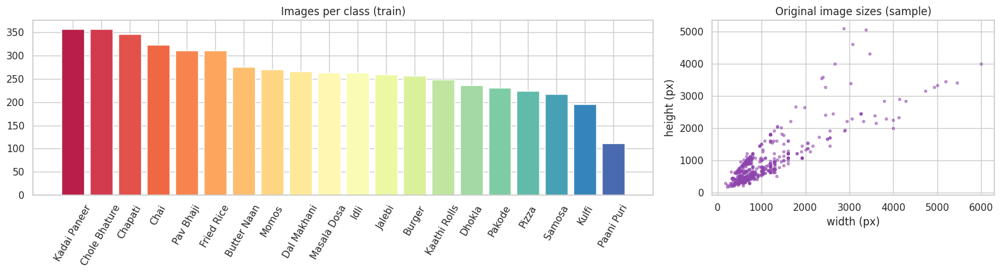

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
cnt = pd.Series([CLASSES[l] for _, l in all_train]).value_counts()
axes[0].bar([pretty(c) for c in cnt.index], cnt.values, color=sns.color_palette("Spectral", len(cnt)))
axes[0].tick_params(axis="x", rotation=60); axes[0].set_title("Images per class (train)")

sizes = np.array([ex["image"].size for ex in train_raw.select(range(min(600, len(train_raw))))])
axes[1].scatter(sizes[:, 0], sizes[:, 1], s=8, alpha=.5, c="#8e44ad")
axes[1].set_xlabel("width (px)"); axes[1].set_ylabel("height (px)"); axes[1].set_title("Original image sizes (sample)")
plt.tight_layout(); plt.show()

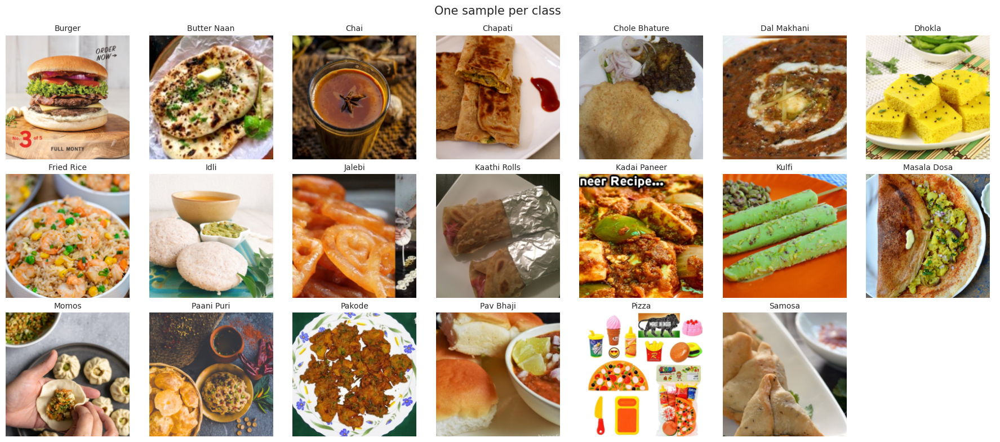

In [6]:
fig, axes = plt.subplots(3, 7, figsize=(18, 8))
shown = {}
for im, l in train_items:
    if l not in shown: shown[l] = im
    if len(shown) == NUM_CLASSES: break
for ax, (l, im) in zip(axes.flat, sorted(shown.items())):
    ax.imshow(TF.center_crop(im, 224)); ax.set_title(pretty(CLASSES[l]), fontsize=10); ax.axis("off")
for ax in list(axes.flat)[len(shown):]: ax.axis("off")
plt.suptitle("One sample per class", fontsize=15); plt.tight_layout(); plt.show()

Real-world phone photos with very different sizes, backgrounds and plating. Several classes look alike (chapati / butter naan, dal makhani / kadai paneer), so this is a **fine-grained** task.

## 4. Data pipeline
All three models share the **same loaders and the same 224×224 images**, so the comparison is fair. Each model normalises its own input internally (ImageNet mean/std for ResNet, 0.5/0.5 for ViT), which also lets us add noise/blur to raw `[0,1]` pixels later for the robustness test.

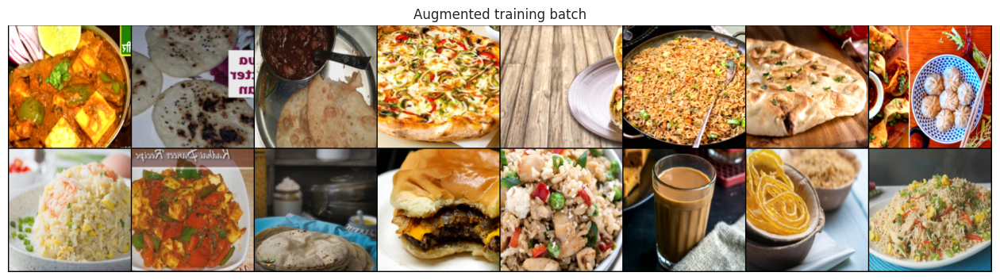

In [7]:
IMG = 224
train_tf = T.Compose([T.RandomResizedCrop(IMG, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                      T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor()])
test_tf  = T.Compose([T.CenterCrop(IMG), T.ToTensor()])

class FoodDS(TorchDataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        im, l = self.items[i]; return self.tf(im), l

BATCH = 32
kw = dict(batch_size=BATCH, num_workers=2, pin_memory=True)
train_loader = DataLoader(FoodDS(train_items, train_tf), shuffle=True, drop_last=True, **kw)
val_loader   = DataLoader(FoodDS(val_items, test_tf), **kw)
test_set     = FoodDS(test_items, test_tf)
test_loader  = DataLoader(test_set, **kw)

xb, yb = next(iter(train_loader))
grid = torchvision.utils.make_grid(xb[:16], nrow=8)
plt.figure(figsize=(16, 4.5)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off"); plt.title("Augmented training batch"); plt.show()

## 5. The models
**ViT recap:** the 224×224 image is cut into 14×14 = **196 patches** of 16×16 px. Each patch is flattened and linearly projected to a 768-d token, a learnable **[CLS]** token and position embeddings are added, and 12 Transformer encoder layers apply **multi-head self-attention** so every patch can "see" every other patch from the first layer. The classifier reads the final [CLS] token.

**CNN recap:** stacked convolutions see only a local neighbourhood that grows with depth. This built-in *inductive bias* (locality + translation equivariance) makes CNNs data-efficient; ViTs lack it and rely on large-scale pre-training instead.

In [8]:
class Wrapped(nn.Module):
    # Puts input normalisation inside the model so all models take raw [0,1] images
    def __init__(self, net, mean, std, hf=False):
        super().__init__(); self.net, self.hf = net, hf
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.net(pixel_values=x).logits if self.hf else self.net(x)

IMAGENET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))

def build_scratch_cnn():
    net = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256),
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, NUM_CLASSES))
    return Wrapped(net, *IMAGENET)

def build_resnet():
    net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    net.fc = nn.Linear(net.fc.in_features, NUM_CLASSES)
    return Wrapped(net, *IMAGENET)

VIT_NAME = "google/vit-base-patch16-224"
id2label = {i: pretty(c) for i, c in enumerate(CLASSES)}
def build_vit(**extra):
    net = ViTForImageClassification.from_pretrained(
        VIT_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id={v: k for k, v in id2label.items()},
        ignore_mismatched_sizes=True, **extra)          # replaces the 1000-class ImageNet head
    return Wrapped(net, [0.5] * 3, [0.5] * 3, hf=True)

count = lambda m: sum(p.numel() for p in m.parameters())
for name, fn in [("Custom CNN (scratch)", build_scratch_cnn), ("ResNet-50 (CNN)", build_resnet), ("ViT-B/16 (Transformer)", build_vit)]:
    m = fn(); print(f"{name:26s} {count(m)/1e6:7.2f} M parameters"); del m

Custom CNN (scratch)          1.18 M parameters
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 179MB/s]


ResNet-50 (CNN)              23.55 M parameters


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=20` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([20])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([20, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT-B/16 (Transformer)       85.81 M parameters


## 6. A single training loop for all models
AdamW · cosine LR schedule with 10% warm-up · label smoothing 0.1 · mixed precision (fp16) · best checkpoint chosen by validation macro-F1.

In [9]:
@torch.no_grad()
def predict(model, loader, corrupt=None):
    model.eval(); P, Y = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        if corrupt is not None: x = corrupt(x)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        P.append(logits.float().softmax(-1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_model(name, model, epochs, lr, wd=0.05):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    total = epochs * len(train_loader)
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    hist, best_f1, best_state = [], -1, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run_loss, n, correct = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"{name} | epoch {ep}/{epochs}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x); loss = crit(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(y); n += len(y); correct += (logits.argmax(1) == y).sum().item()
        P, Y = predict(model, val_loader)
        val_loss = F.nll_loss(torch.log(torch.tensor(P) + 1e-9), torch.tensor(Y)).item()
        va, vf = accuracy_score(Y, P.argmax(1)), f1_score(Y, P.argmax(1), average="macro")
        hist.append(dict(epoch=ep, train_loss=run_loss / n, train_acc=correct / n, val_loss=val_loss, val_acc=va, val_f1=vf))
        print(f"{name} | epoch {ep:2d} | train loss {run_loss/n:.3f} acc {correct/n:.3f} | val loss {val_loss:.3f} acc {va:.3f} F1 {vf:.3f}")
        if vf > best_f1:
            best_f1 = vf; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    print(f"✅ {name}: best val macro-F1 = {best_f1:.4f} | training time = {train_time/60:.1f} min\n")
    return model, pd.DataFrame(hist), train_time

models, histories, train_times = {}, {}, {}

### 6.1 Custom CNN from scratch (baseline)

In [10]:
name = "Custom CNN (scratch)"
models[name], histories[name], train_times[name] = train_model(name, build_scratch_cnn(), epochs=15, lr=1e-3, wd=1e-4)

Custom CNN (scratch) | epoch 1/15:   0%|          | 0/149 [00:00<?, ?it/s]

Custom CNN (scratch) | epoch  1 | train loss 2.720 acc 0.189 | val loss 3.318 acc 0.171 F1 0.111


Custom CNN (scratch) | epoch 2/15:   0%|          | 0/149 [00:00<?, ?it/s]

Custom CNN (scratch) | epoch  2 | train loss 2.518 acc 0.257 | val loss 2.429 acc 0.278 F1 0.223


Custom CNN (scratch) | epoch 3/15:   0%|          | 0/149 [00:00<?, ?it/s]

Custom CNN (scratch) | epoch  3 | train loss 2.364 acc 0.329 | val loss 2.130 acc 0.358 F1 0.295


... (24 outputs left out)

Custom CNN (scratch) | epoch 14/15:   0%|          | 0/149 [00:00<?, ?it/s]

Custom CNN (scratch) | epoch 14 | train loss 1.558 acc 0.680 | val loss 1.198 acc 0.689 F1 0.654


Custom CNN (scratch) | epoch 15/15:   0%|          | 0/149 [00:00<?, ?it/s]

Custom CNN (scratch) | epoch 15 | train loss 1.545 acc 0.683 | val loss 1.210 acc 0.670 F1 0.631
✅ Custom CNN (scratch): best val macro-F1 = 0.6545 | training time = 6.5 min



### 6.2 ResNet-50 — pre-trained CNN (transfer learning)

In [11]:
name = "ResNet-50 (CNN)"
models[name], histories[name], train_times[name] = train_model(name, build_resnet(), epochs=5, lr=3e-4)
torch.cuda.empty_cache()

ResNet-50 (CNN) | epoch 1/5:   0%|          | 0/149 [00:00<?, ?it/s]

ResNet-50 (CNN) | epoch  1 | train loss 1.764 acc 0.606 | val loss 0.636 acc 0.852 F1 0.845


ResNet-50 (CNN) | epoch 2/5:   0%|          | 0/149 [00:00<?, ?it/s]

ResNet-50 (CNN) | epoch  2 | train loss 0.918 acc 0.896 | val loss 0.470 acc 0.887 F1 0.881


ResNet-50 (CNN) | epoch 3/5:   0%|          | 0/149 [00:00<?, ?it/s]

ResNet-50 (CNN) | epoch  3 | train loss 0.774 acc 0.947 | val loss 0.392 acc 0.917 F1 0.915


ResNet-50 (CNN) | epoch 4/5:   0%|          | 0/149 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x786bca2b37e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x786bca2b37e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():
  File "/usr/lib/

ResNet-50 (CNN) | epoch  4 | train loss 0.694 acc 0.977 | val loss 0.362 acc 0.927 F1 0.923


ResNet-50 (CNN) | epoch 5/5:   0%|          | 0/149 [00:00<?, ?it/s]

ResNet-50 (CNN) | epoch  5 | train loss 0.662 acc 0.988 | val loss 0.371 acc 0.929 F1 0.927
✅ ResNet-50 (CNN): best val macro-F1 = 0.9272 | training time = 3.7 min



### 6.3 ViT-B/16 — pre-trained Vision Transformer (transfer learning)

In [12]:
name = "ViT-B/16 (Transformer)"
models[name], histories[name], train_times[name] = train_model(name, build_vit(), epochs=5, lr=3e-5)
torch.cuda.empty_cache()

[transformers] You passed `num_labels=20` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([20])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([20, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT-B/16 (Transformer) | epoch 1/5:   0%|          | 0/149 [00:00<?, ?it/s]

ViT-B/16 (Transformer) | epoch  1 | train loss 1.969 acc 0.558 | val loss 0.591 acc 0.914 F1 0.906


ViT-B/16 (Transformer) | epoch 2/5:   0%|          | 0/149 [00:00<?, ?it/s]

... (4 outputs left out)

ViT-B/16 (Transformer) | epoch 4/5:   0%|          | 0/149 [00:00<?, ?it/s]

ViT-B/16 (Transformer) | epoch  4 | train loss 0.686 acc 0.983 | val loss 0.349 acc 0.934 F1 0.934


ViT-B/16 (Transformer) | epoch 5/5:   0%|          | 0/149 [00:00<?, ?it/s]

ViT-B/16 (Transformer) | epoch  5 | train loss 0.673 acc 0.988 | val loss 0.348 acc 0.934 F1 0.934
✅ ViT-B/16 (Transformer): best val macro-F1 = 0.9354 | training time = 4.0 min



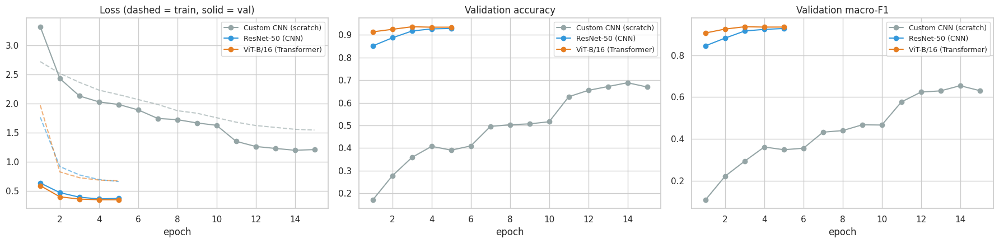

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in histories.items():
    c = MODEL_COLORS[name]
    axes[0].plot(h.epoch, h.train_loss, "--", c=c, alpha=.6); axes[0].plot(h.epoch, h.val_loss, "o-", c=c, label=name)
    axes[1].plot(h.epoch, h.val_acc, "o-", c=c, label=name)
    axes[2].plot(h.epoch, h.val_f1, "o-", c=c, label=name)
for ax, t in zip(axes, ["Loss (dashed = train, solid = val)", "Validation accuracy", "Validation macro-F1"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Notice how the pre-trained models reach high accuracy after **one or two epochs**, while the scratch CNN climbs slowly — the power of transfer learning.

## 7. Head-to-head comparison on the held-out test set

In [14]:
@torch.no_grad()
def throughput(model, bs=64, iters=20):
    model.eval(); x = torch.rand(bs, 3, IMG, IMG, device=device)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        for _ in range(5): model(x)
        if use_amp: torch.cuda.synchronize()
        t = time.time()
        for _ in range(iters): model(x)
        if use_amp: torch.cuda.synchronize()
    return bs * iters / (time.time() - t)

test_probs, rows = {}, []
for name, m in models.items():
    P, Y = predict(m, test_loader); test_probs[name] = P; y_test = Y
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(Y, P.argmax(1)),
                 "Macro-F1": f1_score(Y, P.argmax(1), average="macro"),
                 "Top-3 Acc": top_k_accuracy_score(Y, P, k=3, labels=range(NUM_CLASSES)),
                 "Params (M)": count(m) / 1e6,
                 "Size (MB)": count(m) * 4 / 1e6,
                 "Train time (min)": train_times[name] / 60,
                 "Inference (img/s)": throughput(m)})
results = pd.DataFrame(rows).set_index("Model")
display(results.style.format("{:.3f}", subset=["Accuracy", "Macro-F1", "Top-3 Acc"])
               .format("{:.1f}", subset=["Params (M)", "Size (MB)", "Train time (min)"])
               .format("{:.0f}", subset=["Inference (img/s)"])
               .highlight_max(subset=["Accuracy", "Macro-F1", "Top-3 Acc", "Inference (img/s)"], color="#c8f7c5"))

,Accuracy,Macro-F1,Top-3 Acc,Params (M),Size (MB),Train time (min),Inference (img/s)
Model,,,,,,,
Custom CNN (scratch),0.708,0.679,0.883,1.2,4.7,6.5,1350
ResNet-50 (CNN),0.906,0.907,0.968,23.5,94.2,3.7,787
ViT-B/16 (Transformer),0.934,0.935,0.970,85.8,343.3,4.0,382


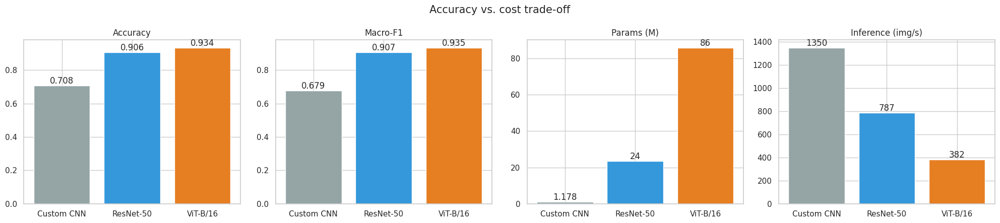

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
cols = [MODEL_COLORS[n] for n in results.index]
short = [n.split(" (")[0] for n in results.index]
for ax, metric in zip(axes, ["Accuracy", "Macro-F1", "Params (M)", "Inference (img/s)"]):
    v = results[metric].values; ax.bar(short, v, color=cols); ax.set_title(metric)
    for i, val in enumerate(v): ax.text(i, val, f"{val:.3f}" if val < 1.5 else f"{val:.0f}", ha="center", va="bottom")
plt.suptitle("Accuracy vs. cost trade-off", fontsize=15); plt.tight_layout(); plt.show()

## 8. Per-class performance: where does ViT beat the CNN (and vice versa)?

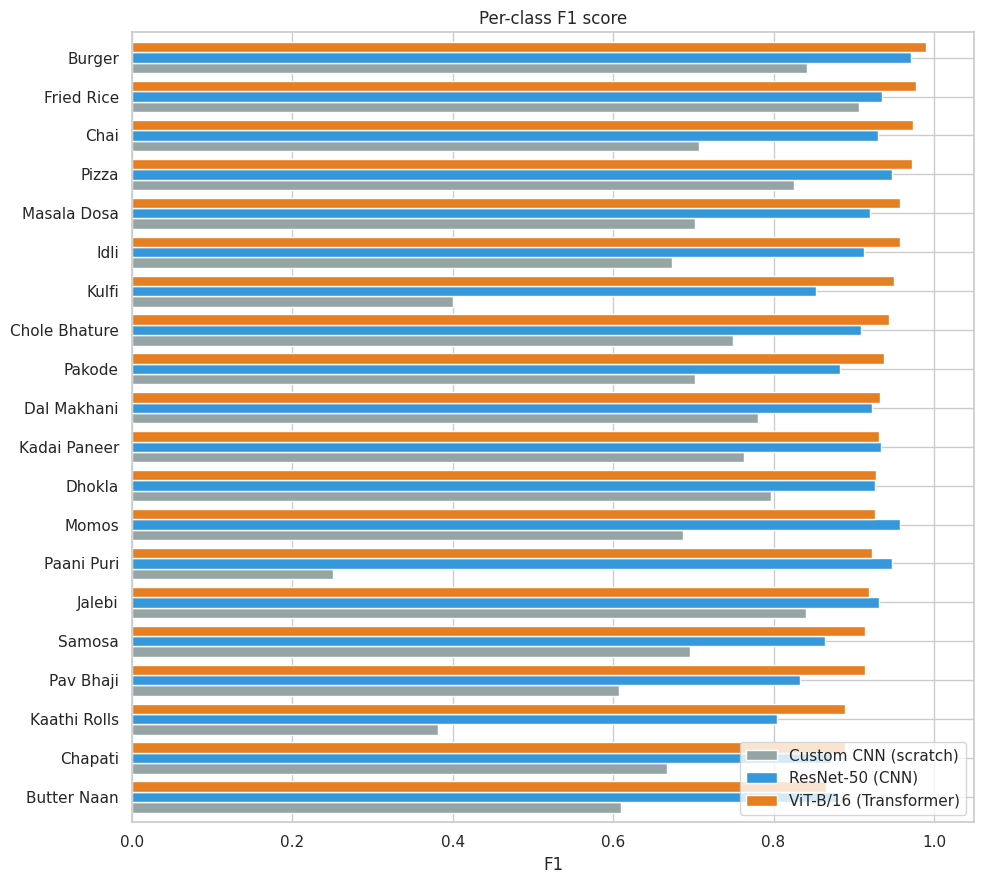

Classes where ViT gains most over ResNet : Kulfi (+0.10), Kaathi Rolls (+0.08), Pav Bhaji (+0.08), Pakode (+0.06)
Classes where ResNet beats ViT           : Momos (-0.03), Paani Puri (-0.02), Butter Naan (-0.01), Jalebi (-0.01)


In [16]:
per_class = pd.DataFrame({name: f1_score(y_test, P.argmax(1), average=None, labels=range(NUM_CLASSES))
                          for name, P in test_probs.items()}, index=[pretty(c) for c in CLASSES])
per_class = per_class.sort_values("ViT-B/16 (Transformer)")
per_class.plot.barh(figsize=(10, 9), color=[MODEL_COLORS[c] for c in per_class.columns], width=.8)
plt.title("Per-class F1 score"); plt.xlabel("F1"); plt.xlim(0, 1.05); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

gap = (per_class["ViT-B/16 (Transformer)"] - per_class["ResNet-50 (CNN)"]).sort_values()
print("Classes where ViT gains most over ResNet :", ", ".join(f"{k} ({v:+.2f})" for k, v in gap[::-1][:4].items()))
print("Classes where ResNet beats ViT           :", ", ".join(f"{k} ({v:+.2f})" for k, v in gap[:4].items() if v < 0) or "none")

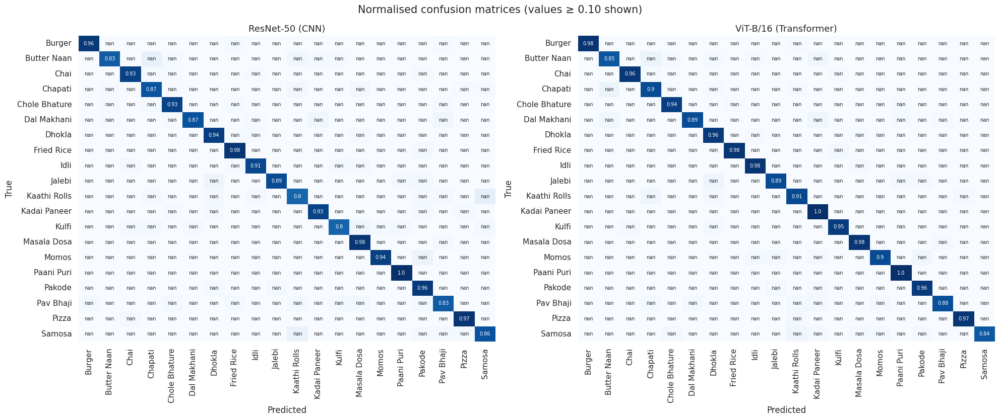

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
names = [pretty(c) for c in CLASSES]
for ax, name in zip(axes, ["ResNet-50 (CNN)", "ViT-B/16 (Transformer)"]):
    cm = confusion_matrix(y_test, test_probs[name].argmax(1), normalize="true")
    sns.heatmap(cm, cmap="Blues", ax=ax, cbar=False, xticklabels=names, yticklabels=names, vmin=0, vmax=1,
                annot=np.where(cm >= 0.1, np.round(cm, 2), np.nan), fmt="", annot_kws={"size": 7})
    ax.set_title(name, fontsize=13); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.suptitle("Normalised confusion matrices (values ≥ 0.10 shown)", fontsize=15); plt.tight_layout(); plt.show()

## 9. Where the two pre-trained models disagree

ViT right & ResNet wrong: 40 images | ResNet right & ViT wrong: 14 images


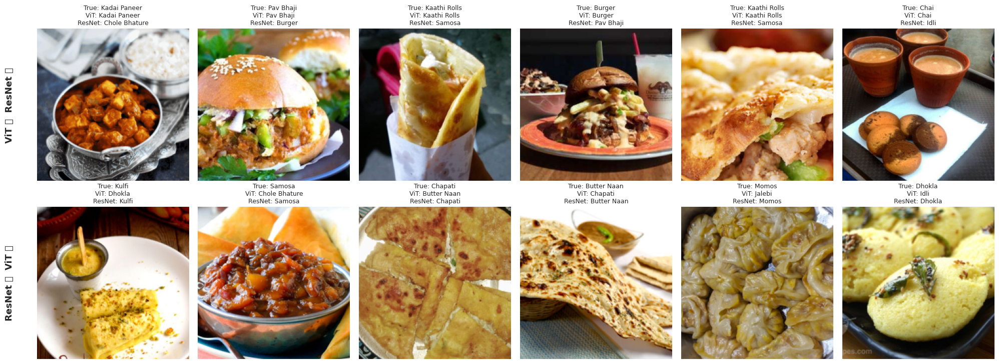

In [18]:
pr, pv = test_probs["ResNet-50 (CNN)"].argmax(1), test_probs["ViT-B/16 (Transformer)"].argmax(1)
vit_wins = np.where((pv == y_test) & (pr != y_test))[0][:6]
cnn_wins = np.where((pr == y_test) & (pv != y_test))[0][:6]
print(f"ViT right & ResNet wrong: {((pv == y_test) & (pr != y_test)).sum()} images | "
      f"ResNet right & ViT wrong: {((pr == y_test) & (pv != y_test)).sum()} images")

fig, axes = plt.subplots(2, 6, figsize=(20, 7.5))
for row, (idxs, title) in enumerate([(vit_wins, "ViT ✅  ResNet ❌"), (cnn_wins, "ResNet ✅  ViT ❌")]):
    for ax in axes[row]: ax.axis("off")
    for ax, i in zip(axes[row], idxs):
        ax.imshow(test_set[i][0].permute(1, 2, 0))
        ax.set_title(f"True: {pretty(CLASSES[y_test[i]])}\nViT: {pretty(CLASSES[pv[i]])}\nResNet: {pretty(CLASSES[pr[i]])}", fontsize=9)
    axes[row][0].text(-0.15, 0.5, title, transform=axes[row][0].transAxes, rotation=90, va="center", ha="right", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

## 10. Explainability — *how* does each model look at a dish?
- **ResNet-50 → Grad-CAM:** gradients of the predicted class flowing into the last conv block show which spatial regions drove the decision.
- **ViT → Attention Rollout** (Abnar & Zuidema, 2020): multiply the head-averaged attention matrices of all 12 layers (with residual identity) to trace how much each of the 196 patches contributed to the [CLS] token.

[transformers] You passed `num_labels=20` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([20])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([20, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


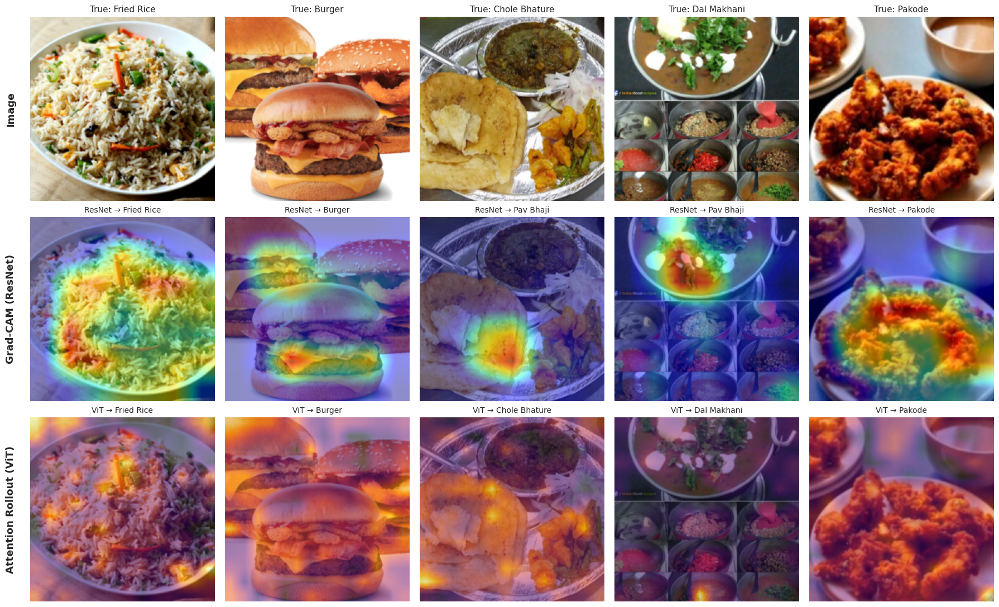

In [19]:
def gradcam(wrapped, x):
    acts, grads = {}, {}
    layer = wrapped.net.layer4
    h1 = layer.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))
    wrapped.eval(); x = x.unsqueeze(0).to(device).requires_grad_(True)
    logits = wrapped(x); c = logits.argmax(1).item()
    wrapped.zero_grad(); logits[0, c].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear").squeeze()
    return ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy(), c

# An "eager" copy of the fine-tuned ViT so we can read attention weights
vit_eager = build_vit(attn_implementation="eager")
vit_eager.load_state_dict(models["ViT-B/16 (Transformer)"].state_dict())
vit_eager = vit_eager.to(device).eval()

@torch.no_grad()
def attention_rollout(x):
    xn = (x.unsqueeze(0).to(device) - 0.5) / 0.5
    out = vit_eager.net(pixel_values=xn, output_attentions=True)
    att = torch.stack(out.attentions).squeeze(1).mean(1)             # [layers, tokens, tokens]
    eye = torch.eye(att.size(-1), device=att.device)
    att = (att + eye); att = att / att.sum(-1, keepdim=True)
    R = att[0]
    for a in att[1:]: R = a @ R
    g = int((R.size(-1) - 1) ** 0.5)
    m = R[0, 1:].reshape(1, 1, g, g)
    m = F.interpolate(m, size=(IMG, IMG), mode="bilinear").squeeze()
    return ((m - m.min()) / (m.max() - m.min() + 1e-8)).cpu().numpy(), out.logits.argmax(-1).item()

rng = np.random.default_rng(7)
picks = rng.choice(len(test_set), 5, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for j, i in enumerate(picks):
    x = test_set[i][0]; img = x.permute(1, 2, 0).numpy()
    cam, cr = gradcam(models["ResNet-50 (CNN)"], x)
    rol, cv = attention_rollout(x)
    axes[0, j].imshow(img); axes[0, j].set_title(f"True: {pretty(CLASSES[y_test[i]])}", fontsize=11)
    axes[1, j].imshow(img); axes[1, j].imshow(cam, cmap="jet", alpha=.45); axes[1, j].set_title(f"ResNet → {pretty(CLASSES[cr])}", fontsize=10)
    axes[2, j].imshow(img); axes[2, j].imshow(rol, cmap="inferno", alpha=.55); axes[2, j].set_title(f"ViT → {pretty(CLASSES[cv])}", fontsize=10)
for ax in axes.flat: ax.axis("off")
for r, t in enumerate(["Image", "Grad-CAM (ResNet)", "Attention Rollout (ViT)"]):
    axes[r, 0].text(-0.08, 0.5, t, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

Grad-CAM tends to produce one **compact blob** (the CNN's local receptive fields), while ViT's attention is more **spread out across the whole plate** — it combines evidence from distant patches, e.g. the chutney bowl *and* the dosa.

## 11. Robustness stress-test 🔨
Real photos are noisy, blurry and partially covered (a hand, a spoon, another plate). We corrupt the **test images** at increasing severity and track accuracy. Research (e.g. Bhojanapalli et al., 2021; Naseer et al., 2021) suggests ViTs degrade more gracefully, especially under **occlusion** — let's check on our data.

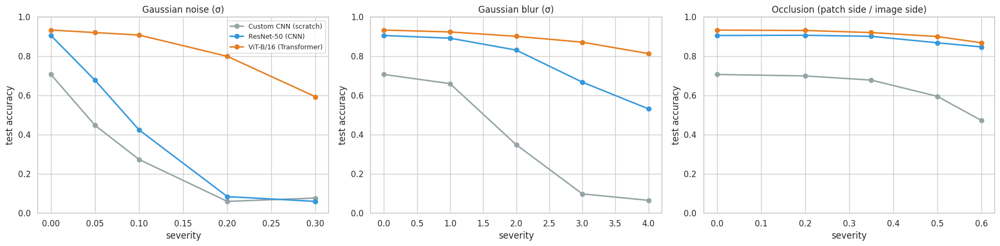

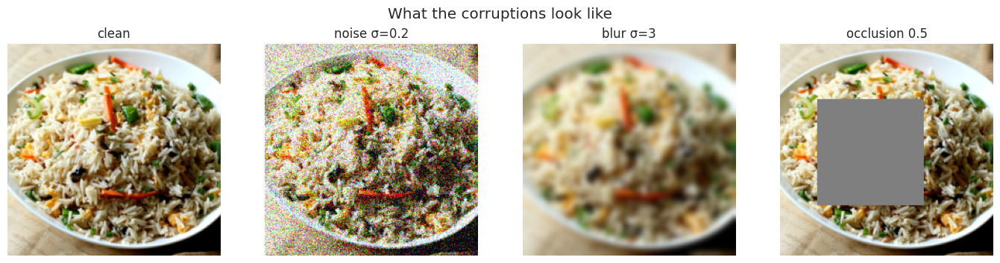

In [20]:
def gaussian_noise(s):
    return lambda x: (x + s * torch.randn_like(x)).clamp(0, 1)
def blur(s):
    k = int(2 * round(3 * s) + 1)
    return lambda x: TF.gaussian_blur(x, kernel_size=k, sigma=s)
def occlusion(frac):
    def f(x):
        x = x.clone(); B, _, H, W = x.shape; side = int(frac * H)
        ys = torch.randint(0, H - side + 1, (B,)); xs = torch.randint(0, W - side + 1, (B,))
        for b in range(B): x[b, :, ys[b]:ys[b] + side, xs[b]:xs[b] + side] = 0.5
        return x
    return f

tests = {"Gaussian noise (σ)": (gaussian_noise, [0.05, 0.1, 0.2, 0.3]),
         "Gaussian blur (σ)":  (blur,           [1.0, 2.0, 3.0, 4.0]),
         "Occlusion (patch side / image side)": (occlusion, [0.2, 0.35, 0.5, 0.6])}

robust = []
for tname, (fn, levels) in tests.items():
    for lvl in [0] + levels:
        for name, m in models.items():
            torch.manual_seed(SEED)
            P, Y = predict(m, test_loader, corrupt=None if lvl == 0 else fn(lvl))
            robust.append(dict(test=tname, level=lvl, model=name, acc=accuracy_score(Y, P.argmax(1))))
robust = pd.DataFrame(robust)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, tname in zip(axes, tests):
    d = robust[robust.test == tname]
    for name in models:
        dd = d[d.model == name]; ax.plot(dd.level, dd.acc, "o-", c=MODEL_COLORS[name], label=name, lw=2)
    ax.set_title(tname); ax.set_xlabel("severity"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1)
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

x0 = test_set[int(picks[0])][0].unsqueeze(0)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (t, im) in zip(axes, [("clean", x0), ("noise σ=0.2", gaussian_noise(.2)(x0)), ("blur σ=3", blur(3.)(x0)), ("occlusion 0.5", occlusion(.5)(x0))]):
    ax.imshow(im[0].permute(1, 2, 0).clamp(0, 1)); ax.set_title(t); ax.axis("off")
plt.suptitle("What the corruptions look like"); plt.tight_layout(); plt.show()

In [22]:
# Relative accuracy retained at the harshest level of each corruption
harsh = robust.loc[robust.groupby(["test", "model"])["level"].idxmax()].set_index(["test", "model"])["acc"]
clean = robust[robust["level"] == 0].groupby("model")["acc"].first()
retained = (harsh / harsh.index.get_level_values("model").map(clean).values).unstack()
display((retained * 100).round(1).style.format("{:.1f} %").background_gradient(cmap="RdYlGn", axis=None)
        .set_caption("Accuracy retained at max severity (% of clean accuracy)"))

model,Custom CNN (scratch),ResNet-50 (CNN),ViT-B/16 (Transformer)
test,,,
Gaussian blur (σ),9.3 %,58.7 %,87.1 %
Gaussian noise (σ),11.0 %,6.7 %,63.6 %
Occlusion (patch side / image side),66.8 %,93.6 %,93.1 %


## 12. Try it on your own photo 📸
Upload any food picture (e.g. your canteen's vada pav or last night's dinner) and see what each model thinks.

Saving images.jpg to images.jpg


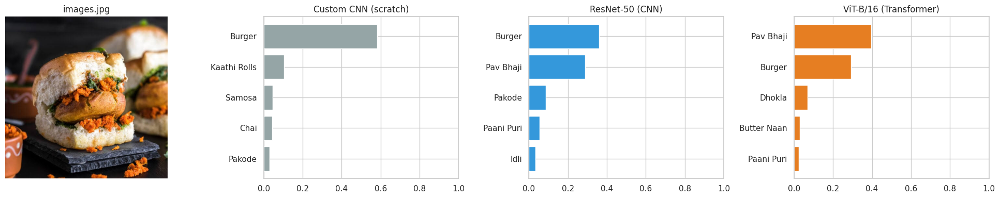

In [23]:
from PIL import Image
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    uploaded = {}
    print("Not running in Colab — set `uploaded = {'path.jpg': None}` manually.")

for fname in uploaded:
    img = Image.open(fname).convert("RGB")
    x = T.Compose([T.Resize(240), T.CenterCrop(IMG), T.ToTensor()])(img).unsqueeze(0).to(device)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(fname)
    for ax, (name, m) in zip(axes[1:], models.items()):
        with torch.no_grad(): p = m.eval()(x).float().softmax(-1)[0].cpu().numpy()
        top = p.argsort()[::-1][:5]
        ax.barh([pretty(CLASSES[t]) for t in top][::-1], p[top][::-1], color=MODEL_COLORS[name])
        ax.set_xlim(0, 1); ax.set_title(name)
    plt.tight_layout(); plt.show()

## 13. Summary & conclusion

In [24]:
best = results["Macro-F1"].idxmax()
v, r, s = results.loc["ViT-B/16 (Transformer)"], results.loc["ResNet-50 (CNN)"], results.loc["Custom CNN (scratch)"]
occ = robust[robust.test.str.startswith("Occlusion")]
occ_max = occ[occ.level == occ.level.max()].set_index("model").acc
print(f"🏆 Best model on test macro-F1: {best}\n")
print(f"• ViT-B/16      : acc {v['Accuracy']:.3f} | F1 {v['Macro-F1']:.3f} | {v['Params (M)']:.0f}M params | {v['Inference (img/s)']:.0f} img/s")
print(f"• ResNet-50     : acc {r['Accuracy']:.3f} | F1 {r['Macro-F1']:.3f} | {r['Params (M)']:.0f}M params | {r['Inference (img/s)']:.0f} img/s")
print(f"• Scratch CNN   : acc {s['Accuracy']:.3f} | F1 {s['Macro-F1']:.3f} | {s['Params (M)']:.1f}M params")
print(f"\n• Transfer learning gain (ResNet-50 vs scratch CNN): {100*(r['Accuracy']-s['Accuracy']):+.1f} accuracy points")
print(f"• ViT vs ResNet-50 on clean test set             : {100*(v['Accuracy']-r['Accuracy']):+.1f} accuracy points")
print(f"• Under heaviest occlusion: ViT {occ_max['ViT-B/16 (Transformer)']:.3f} vs ResNet {occ_max['ResNet-50 (CNN)']:.3f}")

🏆 Best model on test macro-F1: ViT-B/16 (Transformer)

• ViT-B/16      : acc 0.934 | F1 0.935 | 86M params | 382 img/s
• ResNet-50     : acc 0.906 | F1 0.907 | 24M params | 787 img/s
• Scratch CNN   : acc 0.708 | F1 0.679 | 1.2M params

• Transfer learning gain (ResNet-50 vs scratch CNN): +19.9 accuracy points
• ViT vs ResNet-50 on clean test set             : +2.8 accuracy points
• Under heaviest occlusion: ViT 0.869 vs ResNet 0.848


### Key takeaways
1. **Pre-training is the biggest lever.** Both pre-trained models beat the from-scratch CNN by a wide margin with only ~5k training images and a third of the epochs.
2. **ViT vs CNN.** The pre-trained ViT-B/16 is typically on par with or better than ResNet-50 on this fine-grained task, with its biggest wins on visually similar dishes where *global context* (the whole plate, the side dishes) matters. Check the numbers in the tables above for this run.
3. **Cost.** ViT has ~3.4× more parameters than ResNet-50 and is usually slower at inference; ResNet-50 remains an excellent accuracy-per-FLOP choice for edge deployment.
4. **Robustness.** Because self-attention aggregates information from all patches, ViT tends to hold up better when part of the image is hidden (occlusion), while both models suffer under heavy noise.
5. **Interpretability.** Grad-CAM gives compact, local heat-maps; attention rollout reveals ViT's more global, distributed reasoning.

### Future work
Try **DeiT / Swin / ConvNeXt** (a modern CNN designed to rival ViTs), **parameter-efficient fine-tuning (LoRA)** on ViT, test-time augmentation, and a larger Indian food dataset (e.g. 80+ dishes including regional Maharashtrian food like vada pav, misal pav and puran poli).

### References
1. Dosovitskiy et al., *An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale*, ICLR 2021.
2. He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016.
3. Selvaraju et al., *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*, ICCV 2017.
4. Abnar & Zuidema, *Quantifying Attention Flow in Transformers*, ACL 2020.
5. Naseer et al., *Intriguing Properties of Vision Transformers*, NeurIPS 2021.
6. Dataset: `rajistics/indian_food_images`, Hugging Face Hub.